In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [2]:
# Load the data
values = pd.read_csv("../data/raw/Training_set_values.csv")
labels = pd.read_csv("../data/raw/Training_set_labels.csv")

# Merge the two dataframes on the "id" column
train_data = values.merge(
    labels,
    on="id",
    how="outer",
    validate="one_to_one",
    indicator=True
)

print(train_data["_merge"].value_counts())

_merge
both          59400
left_only         0
right_only        0
Name: count, dtype: int64


In [3]:
unmatched = train_data[train_data["_merge"] != "both"]

display(unmatched.head())
print("Unmatched IDs:", len(unmatched))

train_data = train_data.drop(columns="_merge")

,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group,_merge


Unmatched IDs: 0


In [4]:
print("Merged shape:", train_data.shape)
print("Unique IDs:", train_data["id"].nunique())
print("\nTarget counts:")
display(train_data["status_group"].value_counts(dropna=False))

Merged shape: (59400, 41)
Unique IDs: 59400

Target counts:


status_group
functional                 32259
non functional             22824
functional needs repair     4317
Name: count, dtype: int64

#  Identifying identical feature records and conflicting label

In [27]:
feature_cols = [
    col for col in train_data.columns
    if col not in ["id", "status_group"]
]

print("Number of feature columns:", len(feature_cols))

Number of feature columns: 39


In [28]:
#Check for duplicate rows, excluding id

# Select all columns except the ID
columns_without_id = [
    col for col in train_data.columns
    if col != "id"
]

# Identify all rows that have an identical match, excluding ID
duplicate_rows = train_data[
    train_data.duplicated(
        subset=columns_without_id,
        keep=False
    )
].sort_values(by=columns_without_id)

print("Number of rows involved in duplicates:", len(duplicate_rows))

display(duplicate_rows)

Number of rows involved in duplicates: 70


,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group
15003,18713,0.0,2011-07-13,He,0,HE,31.61953,-1.793342e+00,Kahindu,0,...,soft,good,enough,enough,spring,spring,groundwater,improved spring,improved spring,functional
23692,29553,0.0,2011-07-13,He,0,HE,31.61953,-1.793342e+00,Kahindu,0,...,soft,good,enough,enough,spring,spring,groundwater,improved spring,improved spring,functional
6329,7900,0.0,2011-07-18,Government Of Tanzania,0,Government,0.00000,-2.000000e-08,Hospital,0,...,soft,good,insufficient,insufficient,machine dbh,borehole,groundwater,communal standpipe,communal standpipe,functional
22548,28134,0.0,2011-07-18,Government Of Tanzania,0,Government,0.00000,-2.000000e-08,Hospital,0,...,soft,good,insufficient,insufficient,machine dbh,borehole,groundwater,communal standpipe,communal standpipe,functional
54502,68204,0.0,2011-07-18,Government Of Tanzania,0,Government,0.00000,-2.000000e-08,Hospital,0,...,soft,good,insufficient,insufficient,machine dbh,borehole,groundwater,communal standpipe,communal standpipe,functional
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10732,13409,0.0,2013-02-16,Pmo,0,DWE,0.00000,-2.000000e-08,Muungano,0,...,soft,good,enough,enough,shallow well,shallow well,groundwater,hand pump,hand pump,functional needs repair
48946,61256,0.0,2013-02-16,Rwssp,0,DWE,0.00000,-2.000000e-08,Muungano,0,...,soft,good,enough,enough,shallow well,shallow well,groundwater,hand pump,hand pump,functional
55084,68922,0.0,2013-02-16,Rwssp,0,DWE,0.00000,-2.000000e-08,Muungano,0,...,soft,good,enough,enough,shallow well,shallow well,groundwater,hand pump,hand pump,functional
20578,25661,0.0,2013-02-16,Rwssp,0,DWE,0.00000,-2.000000e-08,none,0,...,soft,good,enough,enough,shallow well,shallow well,groundwater,hand pump,hand pump,functional


In [29]:
#Identify identical feature records and conflicting labels


# 1. Select all feature columns, excluding ID and target
feature_cols = [
    col for col in train_data.columns
    if col not in ["id", "status_group"]
]

# 2. Group records with identical feature values
grouped = train_data.groupby(
    feature_cols,
    dropna=False,
    sort=False
)

# 3. Summarise each feature group
group_summary = grouped.agg(
    number_of_records=("id", "size"),
    number_of_unique_labels=("status_group", "nunique")
).reset_index()

# 4. Keep only repeated feature groups
repeated_groups = group_summary[
    group_summary["number_of_records"] > 1
]

# 5. Identify groups with conflicting target labels
conflicting_groups = repeated_groups[
    repeated_groups["number_of_unique_labels"] > 1
]

# 6. Display the summary
print("Number of repeated feature groups:", len(repeated_groups))
print(
    "Total observations in repeated groups:",
    repeated_groups["number_of_records"].sum()
)
print("Groups with conflicting labels:", len(conflicting_groups))

# 7. Display repeated groups and conflicting groups
display(repeated_groups)
display(conflicting_groups)

# 8. Display the original records with conflicting labels
conflicting_records = train_data.merge(
    conflicting_groups[feature_cols],
    on=feature_cols,
    how="inner"
)

display(
    conflicting_records[
        ["id", "status_group"] + feature_cols
    ]
)

Number of repeated feature groups: 35
Total observations in repeated groups: 72
Groups with conflicting labels: 1


,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,basin,...,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,number_of_records,number_of_unique_labels
408,0.0,2013-01-18,Wvt,0,WVT,0.00000,-2.000000e-08,Shule Ya Msingi Mwamigagani,0,Lake Victoria,...,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,2,2
515,0.0,2013-02-16,Dwsp,0,DWE,0.00000,-2.000000e-08,Serengeti,0,Lake Victoria,...,good,enough,enough,other,other,unknown,other,other,2,1
1005,0.0,2012-10-26,Rwsp,0,DWE,0.00000,-2.000000e-08,Sanjo,0,Lake Victoria,...,good,enough,enough,shallow well,shallow well,groundwater,hand pump,hand pump,2,1
1258,0.0,2013-02-16,Dwsp,0,DWE,0.00000,-2.000000e-08,Igolola,0,Lake Victoria,...,good,enough,enough,shallow well,shallow well,groundwater,hand pump,hand pump,2,1
1740,0.0,2013-01-30,Wvt,0,WVT,0.00000,-2.000000e-08,Wvt Tanzania,0,Lake Victoria,...,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,2,1
1752,0.0,2011-07-28,Government Of Tanzania,0,Government,0.00000,-2.000000e-08,Mahakama,0,Lake Victoria,...,unknown,dry,dry,dam,dam,surface,communal standpipe multiple,communal standpipe,2,1
1853,0.0,2011-08-06,Government Of Tanzania,0,Government,0.00000,-2.000000e-08,Bombani,0,Lake Victoria,...,unknown,dry,dry,lake,river/lake,surface,communal standpipe multiple,communal standpipe,2,1
2688,0.0,2012-10-25,Dwsp,0,DWE,0.00000,-2.000000e-08,Wazazi,0,Lake Victoria,...,good,enough,enough,shallow well,shallow well,groundwater,hand pump,hand pump,2,1
3070,0.0,2012-10-26,Holland,0,HOLLAND,0.00000,-2.000000e-08,Jamii,0,Lake Victoria,...,good,enough,enough,shallow well,shallow well,groundwater,hand pump,hand pump,2,1
3435,0.0,2012-10-26,Holland,0,HOLLAND,0.00000,-2.000000e-08,Jamii,0,Lake Victoria,...,good,enough,enough,shallow well,shallow well,groundwater,other,other,2,1


,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,basin,...,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,number_of_records,number_of_unique_labels
408,0.0,2013-01-18,Wvt,0,WVT,0.0,-2.000000e-08,Shule Ya Msingi Mwamigagani,0,Lake Victoria,...,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,2,2


,id,status_group,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,...,payment_type,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group
0,498,functional,0.0,2013-01-18,Wvt,0,WVT,0.0,-2.000000e-08,Shule Ya Msingi Mwamigagani,...,never pay,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe
1,58343,functional needs repair,0.0,2013-01-18,Wvt,0,WVT,0.0,-2.000000e-08,Shule Ya Msingi Mwamigagani,...,never pay,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe


In [30]:
print("Records in conflicting group:", len(conflicting_records))
print(
    conflicting_records["status_group"]
    .value_counts()
)

Records in conflicting group: 2
status_group
functional                 1
functional needs repair    1
Name: count, dtype: int64


In [31]:
# 1. Count duplicates across all columns
duplicates_all_columns = train_data.duplicated().sum()

# 2. Select feature columns, excluding ID and target
feature_cols = [
    col for col in train_data.columns
    if col not in ["id", "status_group"]
]

# 3. Count duplicates based on feature columns only
duplicates_features = train_data.duplicated(
    subset=feature_cols
).sum()

# 4. Display the results
print("Duplicates across all columns:", duplicates_all_columns)
print("Duplicates based on features only:", duplicates_features)

Duplicates across all columns: 0
Duplicates based on features only: 37


#Now identify groups containing conflicting labels.

#Applying the cleaning rules

In [32]:
clean_data = train_data.copy(deep=True)

print("Original shape:", train_data.shape)
print("Working copy shape:", clean_data.shape)

Original shape: (59400, 41)
Working copy shape: (59400, 41)


In [33]:
numeric_columns = [
    "amount_tsh",
    "gps_height",
    "longitude",
    "latitude",
    "population",
    "construction_year"
]

for col in numeric_columns:
    if col in clean_data.columns:
        clean_data[col] = pd.to_numeric(
            clean_data[col],
            errors="coerce"
        )

In [34]:
#checking outliers in numerical columns

clean_data

,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group
0,0,0.0,2012-11-13,Tasaf,0,TASAF,33.125828,-5.118154,Mratibu,0,...,milky,milky,enough,enough,shallow well,shallow well,groundwater,hand pump,hand pump,non functional
1,1,0.0,2011-03-05,Shipo,1978,SHIPO,34.770717,-9.395642,none,0,...,soft,good,enough,enough,shallow well,shallow well,groundwater,hand pump,hand pump,functional
2,2,0.0,2011-03-27,Lvia,0,LVIA,36.115056,-6.279268,Bombani,0,...,soft,good,insufficient,insufficient,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe,functional
3,3,10.0,2013-06-03,Germany Republi,1639,CES,37.147432,-3.187555,Area 7 Namba 5,0,...,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
4,4,0.0,2011-03-22,Cmsr,0,CMSR,36.164893,-6.099289,Ezeleda,0,...,soft,good,dry,dry,shallow well,shallow well,groundwater,hand pump,hand pump,non functional
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59395,74240,0.0,2013-03-22,World Vision,1183,World vision,37.007726,-3.280868,Upendo Primary School,0,...,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional
59396,74242,0.0,2011-04-12,Danida,0,DANIDA,33.724987,-8.940758,Kwa Mvulula,0,...,soft,good,enough,enough,river,river/lake,surface,communal standpipe,communal standpipe,functional
59397,74243,0.0,2012-11-13,Ministry Of Water,1188,Hesawa,33.963539,-1.429477,Kwa Wambura Msege,0,...,soft,good,enough,enough,lake,river/lake,surface,communal standpipe multiple,communal standpipe,non functional
59398,74246,50.0,2011-03-07,Ruthe,1428,Ruthe,35.630481,-7.710549,none,0,...,soft,good,dry,dry,spring,spring,groundwater,communal standpipe,communal standpipe,non functional


In [35]:
#Treat zero population and construction year as unknown

clean_data["population"] = clean_data["population"].replace(0, np.nan)

clean_data["construction_year"] = clean_data[
    "construction_year"
].replace(0, np.nan)

In [36]:
# Parse the recording date and calculate pump age

clean_data["date_recorded"] = pd.to_datetime(
    clean_data["date_recorded"],
    errors="coerce"
)

clean_data["pump_age"] = (
    clean_data["date_recorded"].dt.year
    - clean_data["construction_year"]
)

In [37]:
#setting negative ages to missing 
clean_data.loc[
    clean_data["pump_age"] < 0,
    "pump_age"
] = np.nan

In [38]:
print("Missing recording dates:", clean_data["date_recorded"].isna().sum())
print("Missing construction years:", clean_data["construction_year"].isna().sum())
print("Missing pump ages:", clean_data["pump_age"].isna().sum())

display(clean_data["pump_age"].describe())

Missing recording dates: 0
Missing construction years: 20709
Missing pump ages: 20718


count    38682.000000
mean        15.360245
std         12.490610
min          0.000000
25%          5.000000
50%         13.000000
75%         25.000000
max         53.000000
Name: pump_age, dtype: float64

In [39]:
#dropping num_private
if "num_private" in clean_data.columns:
    clean_data = clean_data.drop(columns=["num_private"])

In [40]:
#checking missing values and data types
missing_summary = pd.DataFrame({
    "missing_count": clean_data.isna().sum(),
    "missing_percent": clean_data.isna().mean().mul(100).round(2),
    "data_type": clean_data.dtypes.astype(str)
})

missing_summary = missing_summary.sort_values(
    "missing_percent",
    ascending=False
)

display(missing_summary)

,missing_count,missing_percent,data_type
scheme_name,28810,48.50,str
population,21381,35.99,float64
pump_age,20718,34.88,float64
construction_year,20709,34.86,float64
scheme_management,3878,6.53,str
installer,3655,6.15,str
funder,3637,6.12,str
public_meeting,3334,5.61,object
permit,3056,5.14,object
subvillage,371,0.62,str


In [41]:
display(clean_data.select_dtypes(include="number").describe().T)

,count,mean,std,min,25%,50%,75%,max
id,59400.0,37115.131768,21453.128371,0.00000,18519.750000,37061.500000,55656.500000,7.424700e+04
amount_tsh,59400.0,317.650385,2997.574558,0.00000,0.000000,0.000000,20.000000,3.500000e+05
gps_height,59400.0,668.297239,693.116350,-90.00000,0.000000,369.000000,1319.250000,2.770000e+03
longitude,59400.0,34.077427,6.567432,0.00000,33.090347,34.908743,37.178387,4.034519e+01
latitude,59400.0,-5.706033,2.946019,-11.64944,-8.540621,-5.021597,-3.326156,-2.000000e-08
region_code,59400.0,15.297003,17.587406,1.00000,5.000000,12.000000,17.000000,9.900000e+01
district_code,59400.0,5.629747,9.633649,0.00000,2.000000,3.000000,5.000000,8.000000e+01
population,38019.0,281.087167,564.687660,1.00000,40.000000,150.000000,324.000000,3.050000e+04
construction_year,38691.0,1996.814686,12.472045,1960.00000,1987.000000,2000.000000,2008.000000,2.013000e+03
pump_age,38682.0,15.360245,12.490610,0.00000,5.000000,13.000000,25.000000,5.300000e+01


In [42]:
# checking outliers in numerical column

# Columns to check for outliers
numerical_cols = [
    "gps_height",
    "population",
    "pump_age"
]

outlier_results = []

for col in numerical_cols:

    values = clean_data[col].dropna()

    # Exclude zero population because it represents unknown population
    if col == "population":
        values = values[values != 0]

    # Calculate quartiles and IQR
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    # Calculate outlier boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify outliers
    outliers = values[
        (values < lower_bound) | (values > upper_bound)
    ]

    outlier_results.append({
        "column": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": len(outliers),
        "outlier_percentage": (len(outliers) / len(values)) * 100
    })

# Display outlier summary
outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,column,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
0,gps_height,0.0,1319.25,1319.25,-1978.88,3298.12,0,0.0
1,population,40.0,324.00,284.00,-386.00,750.00,2473,6.5
2,pump_age,5.0,25.00,20.00,-25.00,55.00,0,0.0


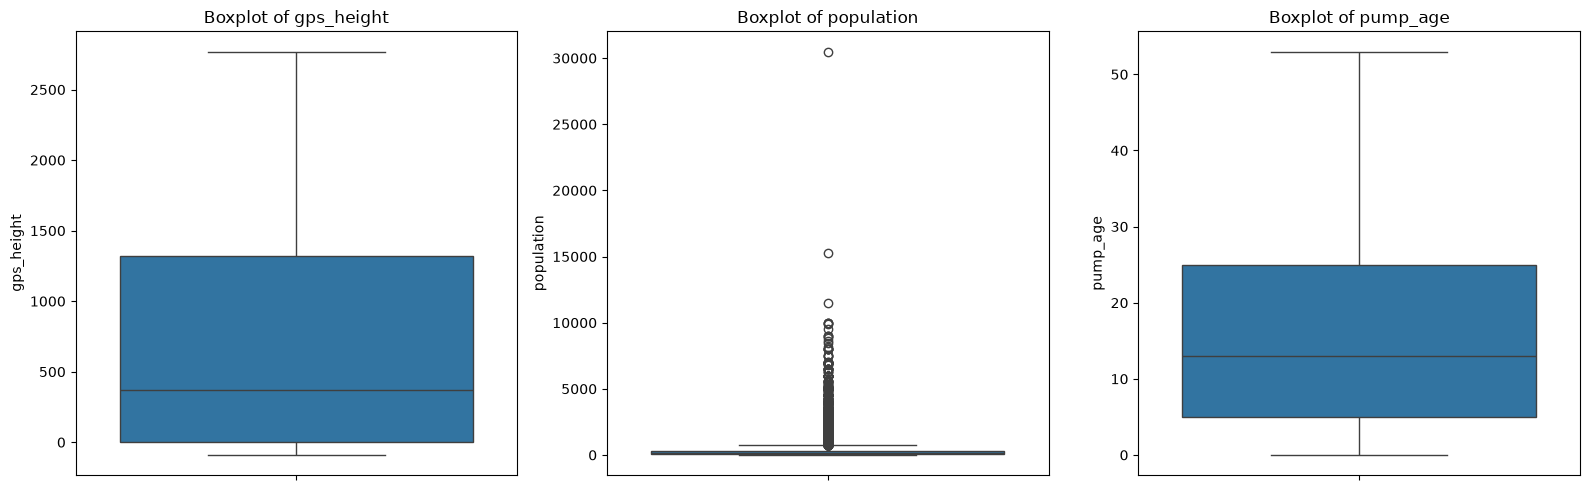

In [43]:
#Visualise the outliers using boxplots

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, numerical_cols):

    sns.boxplot(
        y=clean_data[col],
        ax=ax
    )

    ax.set_title(f"Boxplot of {col}")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

In [44]:
# Based on decision D11, you should preserve the original longitude and latitude values in clean_data, 
# but create a separate geographical validity flag to identify coordinates that should not be used for maps 
# and distance calculations.


#Applying the agreed geographical screening range
#D11 decision specifies:
# Longitude: 29 to 41
# Latitude: -12.5 to -0.9

# Create a geographical validity flag
clean_data["geo_valid"] = (
    clean_data["longitude"].between(29, 41)
    & clean_data["latitude"].between(-12.5, -0.9)
)

# Summarise geographical screening results
print("Geographically suitable records:",
      clean_data["geo_valid"].sum())

print("Geographically unsuitable records:",
      (~clean_data["geo_valid"]).sum())

print("Missing longitude:",
      clean_data["longitude"].isna().sum())

print("Missing latitude:",
      clean_data["latitude"].isna().sum())

Geographically suitable records: 57588
Geographically unsuitable records: 1812
Missing longitude: 0
Missing latitude: 0


The codes above help to identify geographically unsuitable records without deleting or changing the original coordinates.

It checks whether each record's longitude and latitude fall within the agreed geographical ranges.
- True: Both coordinates fall within the specified ranges.
- False: At least one coordinate falls outside the ranges or is missing.
It also gives you counts of suitable and unsuitable records.

The geo_valid column identifies records that pass both coordinate checks.

In [45]:
#inspecting unsuitable coordinates

# Select records outside the geographical screening range
unsuitable_locations = clean_data[
    ~clean_data["geo_valid"]
]

display(
    unsuitable_locations[
        ["id", "longitude", "latitude", "region", "district_code"]
    ].head(20)
)

,id,longitude,latitude,region,district_code
12,15,0.0,-2.000000e-08,Mwanza,2
43,50,0.0,-2.000000e-08,Mwanza,6
68,81,0.0,-2.000000e-08,Mwanza,2
114,137,0.0,-2.000000e-08,Mwanza,6
163,194,0.0,-2.000000e-08,Shinyanga,1
226,274,0.0,-2.000000e-08,Mwanza,6
236,287,0.0,-2.000000e-08,Mwanza,2
266,323,0.0,-2.000000e-08,Mwanza,2
356,439,0.0,-2.000000e-08,Shinyanga,1
408,498,0.0,-2.000000e-08,Shinyanga,1


The above helps to extract records that failed the geographical screening.

You can inspect their IDs, longitude, latitude, region and district to understand why they failed.

This helps identify potentially invalid or unusual geographical records.

In [46]:
#Use the geographical flag for mapping
# When preparing data for maps or distance calculations, use:
geo_data = clean_data[
    clean_data["geo_valid"]
].copy()

The above creates a separate DataFrame containing only records that passed the geographical screening.

You can use this DataFrame for:
- Mapping water points.
- Calculating geographical distances.
- Analysing geographical distributions.

Original clean_data remains unchanged apart from the additional geo_valid flag.

In [47]:
categorical_columns = clean_data.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for col in categorical_columns:
    print(f"\n{col}")
    print(clean_data[col].value_counts(dropna=False))


funder
funder
Government Of Tanzania    9084
NaN                       3637
Danida                    3114
Hesawa                    2202
Rwssp                     1374
                          ... 
Bra                          1
Tredsp                       1
Irevea Sister Water          1
Said Omari                   1
Pius Msekwa                  1
Name: count, Length: 1897, dtype: int64

installer
installer
DWE                  17402
NaN                   3655
Government            1825
RWE                   1206
Commu                 1060
                     ...  
GDP                      1
Simon Lusambi            1
BRA                      1
Ardhi Water Wells        1
Said Omari               1
Name: count, Length: 2146, dtype: int64

wpt_name
wpt_name
none                 3563
Shuleni              1748
Zahanati              830
Msikitini             535
Kanisani              323
                     ... 
Makuru Mchaba           1
Kwa Mzee Onyenge        1
Kwa Lugendo        

In [48]:
related_pairs = [
    ("quantity", "quantity_group"),
    ("extraction_type", "extraction_type_group"),
    ("extraction_type_group", "extraction_type_class"),
    ("management", "management_group"),
    ("payment", "payment_type"),
    ("water_quality", "quality_group"),
    ("source", "source_type"),
    ("source_type", "source_class"),
    ("waterpoint_type", "waterpoint_type_group")
]

for col1, col2 in related_pairs:
    if col1 in clean_data.columns and col2 in clean_data.columns:
        equal = clean_data[col1].eq(clean_data[col2]) | (
            clean_data[col1].isna() & clean_data[col2].isna()
        )

        print(
            f"{col1} vs {col2}: "
            f"{equal.mean() * 100:.2f}% identical"
        )

quantity vs quantity_group: 100.00% identical
extraction_type vs extraction_type_group: 95.84% identical
extraction_type_group vs extraction_type_class: 67.27% identical
management vs management_group: 5.34% identical
payment vs payment_type: 58.18% identical
water_quality vs quality_group: 13.02% identical
source vs source_type: 62.30% identical
source_type vs source_class: 0.00% identical
waterpoint_type vs waterpoint_type_group: 89.73% identical


In [52]:
#analyse how pump functionality differs across categories of categorical variables,

#For example, to examine pump functionality by water_quality:

# Cross-tabulation with counts
quality_counts = pd.crosstab(
    clean_data["water_quality"],
    clean_data["status_group"],
    dropna=False
)

# Calculate percentages within each water-quality category
quality_percentages = pd.crosstab(
    clean_data["water_quality"],
    clean_data["status_group"],
    normalize="index",
    dropna=False
) * 100

# Display sample sizes
print("Number of observations in each category:")
display(quality_counts.sum(axis=1))

print("Pump state percentages within each category:")
display(quality_percentages.round(2))

Number of observations in each category:


water_quality
coloured                490
fluoride                200
fluoride abandoned       17
milky                   804
salty                  4856
salty abandoned         339
soft                  50818
unknown                1876
dtype: int64

Pump state percentages within each category:


status_group,functional,functional needs repair,non functional
water_quality,,,
coloured,50.20,11.02,38.78
fluoride,75.50,6.50,18.00
fluoride abandoned,35.29,0.00,64.71
milky,54.48,1.74,43.78
salty,45.72,4.63,49.65
salty abandoned,51.33,21.24,27.43
soft,56.59,7.68,35.72
unknown,14.07,1.87,84.06


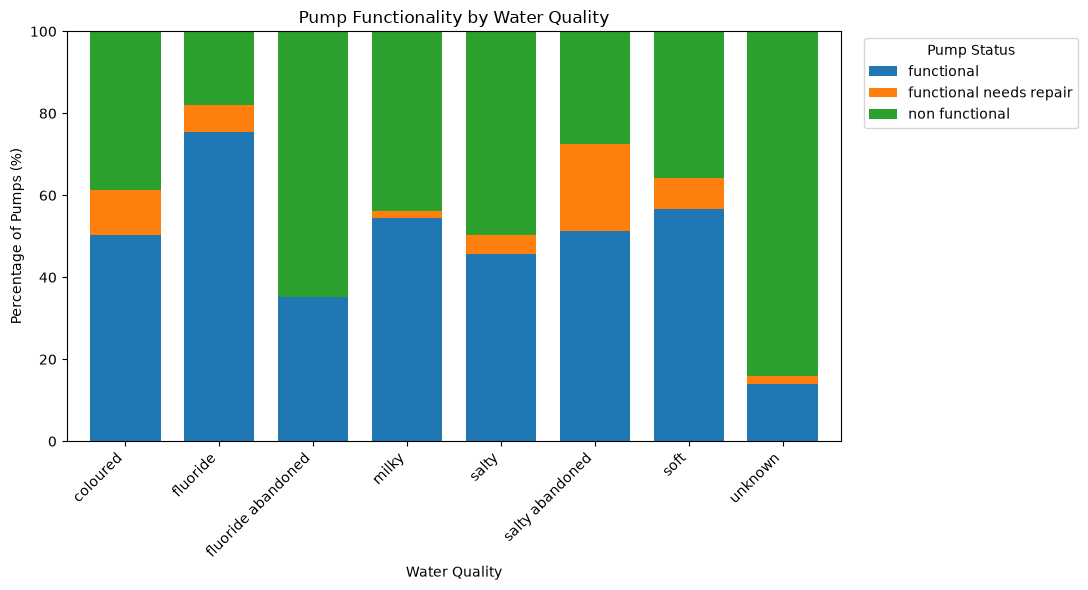

In [53]:
#visualising

# Calculate pump-state percentages within each water-quality category
quality_percentages = pd.crosstab(
    clean_data["water_quality"].fillna("Missing"),
    clean_data["status_group"],
    normalize="index"
) * 100

# Plot
ax = quality_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    width=0.75
)

ax.set_title("Pump Functionality by Water Quality")
ax.set_xlabel("Water Quality")
ax.set_ylabel("Percentage of Pumps (%)")
ax.set_ylim(0, 100)
ax.legend(title="Pump Status", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

We can do the above for other feature of choice 

In [54]:
# Get all unique funder names and their frequencies
funder_summary = (
    clean_data["funder"]
    .value_counts(dropna=False)
    .rename_axis("funder")
    .reset_index(name="frequency")
)

print("Number of unique funder values:", clean_data["funder"].nunique(dropna=False))
print("Total funder categories, including missing:", len(funder_summary))

# Display all values without truncation
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(funder_summary)

Number of unique funder values: 1897
Total funder categories, including missing: 1897


,funder,frequency
0,Government Of Tanzania,9084
1,NaN,3637
2,Danida,3114
3,Hesawa,2202
4,Rwssp,1374
5,World Bank,1349
6,Kkkt,1287
7,World Vision,1246
8,Unicef,1057
9,Tasaf,877


So many errors in the name of funder e.g Ogovermnent, overnment and many more ,
how do we clean this ?

In [55]:
installer_summary = (
    clean_data["installer"]
    .value_counts(dropna=False)
    .rename_axis("installer")
    .reset_index(name="frequency")
)

print("Number of unique installer values:", clean_data["installer"].nunique(dropna=False))
print("Total installer categories, including missing:", len(installer_summary))

# Display all values without truncation
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(installer_summary)

Number of unique installer values: 2146
Total installer categories, including missing: 2146


,installer,frequency
0,DWE,17402
1,NaN,3655
2,Government,1825
3,RWE,1206
4,Commu,1060
5,DANIDA,1050
6,KKKT,898
7,Hesawa,840
8,0,777
9,TCRS,707


Recommendation
- Feature selection: Exclude funder and installer from the initial model.

In [56]:
#cardinality
categorical_cols = train_data.select_dtypes(
    include=["object", "category", "string"]
).columns

cardinality_summary = pd.DataFrame({
    "unique_values": train_data[categorical_cols].nunique(),
    "missing_values": train_data[categorical_cols].isna().sum(),
    "missing_percent": (
        train_data[categorical_cols].isna().mean() * 100
    ).round(2)
})

cardinality_summary["unique_to_nonmissing_ratio"] = (
    cardinality_summary["unique_values"]
    / train_data[categorical_cols].count().replace(0, np.nan)
).round(3)

cardinality_summary = cardinality_summary.sort_values(
    "unique_values",
    ascending=False
)

display(cardinality_summary)

,unique_values,missing_values,missing_percent,unique_to_nonmissing_ratio
wpt_name,37399,2,0.00,0.630
subvillage,19287,371,0.62,0.327
scheme_name,2695,28810,48.50,0.088
installer,2145,3655,6.15,0.038
ward,2092,0,0.00,0.035
funder,1896,3637,6.12,0.034
date_recorded,356,0,0.00,0.006
lga,125,0,0.00,0.002
region,21,0,0.00,0.000
extraction_type,18,0,0.00,0.000


Recommendation
1. For categorical variables, do not replace missing values with the most frequent category automatically.

Pipeline for modelling

In [57]:
# Using feature groups

# Groups of related features
FEATURE_GROUPS = {

    "technical": [
        "extraction_type",
        "extraction_type_class",
        "waterpoint_type",
        "source_type"
    ],

    "management": [
        "management",
        "management_group",
        "payment",
        "payment_type",
        "scheme_management",
        "permit",
        "public_meeting"
    ],

    "water_quality": [
        "water_quality"
    ],

    "numeric": [
        "amount_tsh",
        "gps_height",
        "population"
    ],

    "age": [
        "pump_age"
    ],

    "quantity": [
        "quantity",
        "quantity_group"
    ],

    "location": [
        "region",
        "basin",
        "lga",
        "longitude",
        "latitude"
    ]
}


FEATURE_GROUPS approach is a good idea.
It allows you to compare different combinations of features without manually changing your pipeline every time.

In [58]:
# Feature groups to include in the first baseline
ACTIVE_GROUPS = [
    "technical",
    "management",
    "water_quality",
    "numeric",
    "age",
    "location"
]

# Combine selected groups
selected_features = []

for group in ACTIVE_GROUPS:
    selected_features.extend(FEATURE_GROUPS[group])

# Keep only columns available in clean_data
selected_features = [
    col for col in selected_features
    if col in clean_data.columns
]

# Remove high-cardinality columns from the baseline
excluded_high_cardinality = [
    "wpt_name",
    "subvillage",
    "scheme_name",
    "installer",
    "funder",
    "ward"
]

selected_features = [
    col for col in selected_features
    if col not in excluded_high_cardinality
]

# Remove duplicate column names from the feature list
selected_features = list(dict.fromkeys(selected_features))

print("Selected features:")
print(selected_features)

print("\nNumber of selected features:", len(selected_features))

Selected features:
['extraction_type', 'extraction_type_class', 'waterpoint_type', 'source_type', 'management', 'management_group', 'payment', 'payment_type', 'scheme_management', 'permit', 'public_meeting', 'water_quality', 'amount_tsh', 'gps_height', 'population', 'pump_age', 'region', 'basin', 'lga', 'longitude', 'latitude']

Number of selected features: 21


Preparing X and y
- X contains the selected predictors.
- y contains the target, status_group.
- id is kept separately for tracking, not modelling.
We will use your existing clean_data and leave it unchanged.

In [59]:
# Create modelling features and target
X = clean_data[selected_features].copy()
y = clean_data["status_group"].copy()

# Keep IDs separately
record_ids = clean_data["id"].copy()

# Treat zero population as missing, according to the project decision
if "population" in X.columns:
    X["population"] = X["population"].replace(0, np.nan)

# Check
print("Features:", X.shape)
print("Target:", y.shape)

print("\nTarget distribution:")
display(y.value_counts())

Features: (59400, 21)
Target: (59400,)

Target distribution:


status_group
functional                 32259
non functional             22824
functional needs repair     4317
Name: count, dtype: int64

Spliting data into training and validation

Why not  use train_test_split?

Because the earlier duplicate analysis identified 35 groups of repeated feature combinations, containing 72 observations.

If identical feature records appear in both training and validation, the validation result may be overly optimistic.

Therefore, we will use StratifiedGroupKFold:
- Stratified: tries to maintain the proportions of the three target classes.
- Group: ensures identical selected feature combinations stay together.
- Five folds: uses approximately four folds for training and one for validation.

In [60]:
from sklearn.model_selection import StratifiedGroupKFold

# Identify records with identical selected feature values
duplicate_groups = X.groupby(
    list(X.columns),
    dropna=False,
    sort=False
).ngroup()

# Create the splitter
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate the split
train_idx, val_idx = next(
    splitter.split(X, y, groups=duplicate_groups)
)

# Training data
X_train = X.iloc[train_idx].copy()
y_train = y.iloc[train_idx].copy()

# Validation data
X_val = X.iloc[val_idx].copy()
y_val = y.iloc[val_idx].copy()

# Keep corresponding IDs
id_train = record_ids.iloc[train_idx].copy()
id_val = record_ids.iloc[val_idx].copy()

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("\nTraining records:", len(X_train))
print("Validation records:", len(X_val))

# Confirm no feature groups cross between the two sets
assert set(duplicate_groups.iloc[train_idx]).isdisjoint(
    set(duplicate_groups.iloc[val_idx])
)

print("\nIdentical feature groups are kept within one split.")

Training features: (47520, 21)
Validation features: (11880, 21)

Training records: 47520
Validation records: 11880

Identical feature groups are kept within one split.


In [61]:
# Checking the splitting before modelling
split_summary = pd.DataFrame({
    "Full dataset (%)": y.value_counts(normalize=True) * 100,
    "Training (%)": y_train.value_counts(normalize=True) * 100,
    "Validation (%)": y_val.value_counts(normalize=True) * 100
}).fillna(0)

display(split_summary.round(2))

,Full dataset (%),Training (%),Validation (%)
status_group,,,
functional,54.31,54.31,54.31
non functional,38.42,38.42,38.43
functional needs repair,7.27,7.27,7.26


In [62]:
#checking missing values

missing_summary = pd.DataFrame({
    "Training missing": X_train.isna().sum(),
    "Validation missing": X_val.isna().sum()
})

display(missing_summary)

,Training missing,Validation missing
extraction_type,0,0
extraction_type_class,0,0
waterpoint_type,0,0
source_type,0,0
management,0,0
management_group,0,0
payment,0,0
payment_type,0,0
scheme_management,3066,812
permit,2455,601


In [63]:
# checking unseen categories.

for col in X_train.select_dtypes(
    include=["object", "category", "string"]
).columns:

    train_values = set(X_train[col].dropna().unique())
    validation_values = set(X_val[col].dropna().unique())

    unseen = validation_values - train_values

    print(f"{col}: {len(unseen)} unseen categories")

extraction_type: 0 unseen categories
extraction_type_class: 0 unseen categories
waterpoint_type: 0 unseen categories
source_type: 0 unseen categories
management: 0 unseen categories
management_group: 0 unseen categories
payment: 0 unseen categories
payment_type: 0 unseen categories
scheme_management: 0 unseen categories
permit: 0 unseen categories
public_meeting: 0 unseen categories
water_quality: 0 unseen categories
region: 0 unseen categories
basin: 0 unseen categories
lga: 0 unseen categories


#Build the baseline preprocessing pipeline

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Identify numerical and categorical columns from selected features
numerical_features = [
    col for col in X_train.columns
    if col in clean_data.select_dtypes(include="number").columns
]

categorical_features = [
    col for col in X_train.columns
    if col not in numerical_features
]

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="__MISSING__"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=0.01
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Complete baseline pipeline
baseline_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

* Notice that min_frequency=0.01 helps control the number of encoded categories, particularly for lga.

We can start with logistic regression as the first baseline classifier.

In [ ]:
# Fit using training data only
baseline_pipeline.fit(X_train, y_train)

# Predict using validation data
y_pred = baseline_pipeline.predict(X_val)

print("Baseline model trained successfully.")

In [ ]:
#Evaluate the baseline 

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("Validation accuracy:")
print(round(accuracy_score(y_val, y_pred), 4))

print("\nClassification report:")
print(classification_report(y_val, y_pred, zero_division=0))

# Confusion matrix
cm = confusion_matrix(
    y_val,
    y_pred,
    labels=baseline_pipeline.classes_
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=baseline_pipeline.classes_
)

display_matrix.plot(cmap="Blues", values_format="d")
plt.xticks(rotation=30)
plt.title("Baseline Logistic Regression")
plt.tight_layout()
plt.show()

How to use feature groups in later experiments
This is where the FEATURE_GROUPS approach becomes particularly useful.

You can compare models by switching feature groups on or off.

Summary

Prepared the water pump dataset for baseline modelling by reviewing the data structure, checking for duplicate records, and assessing feature quality. Identified repeated feature combinations, including one group with conflicting target labels, and documented the findings. Reviewed numerical and categorical features, missing values, high-cardinality columns, and potential data quality issues to guide feature selection and preprocessing. Preserved the original records and labels for subsequent modelling.